# Notebook 06: Pembersihan Data Deterministik (*Data Cleaning*)

Setelah `splits.parquet` dan target proksi 14 hari dikunci di `05_data_selection.ipynb`, langkah selanjutnya adalah membersihkan anomali fisik dan memisahkan hari valid dari artefak sensor mati **tanpa memperkenalkan kebocoran data (*data leakage*)**.

Prinsip pembersihan kita di sini ketat dan konservatif:
- **Hanya lakukan koreksi berbasis hukum fisika/domain lokal** (misalnya durasi tidur tidak mungkin kurang dari 0 jam, atau hari non-valid NHANES dikeluarkan), **jangan pernah** melakukan imputasi rata-rata global di tahap ini (karena rata-rata global akan mencampurkan informasi pasien dari fold uji ke data latih).
- **Pertahankan nilai kosong (*missingness*) sebagai sinyal informatif**, bukan ditambal angka tebakan, agar gerbang `ABSTAIN` di hilir tetap mengetahui kapan sensor tidak dapat dipercaya.

Sel pertama memuat `splits.parquet` (`22.544` baris catatan seleksi lintas sumber) beserta tabel ponsel mentah.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

with open(ROOT / "config.json", "r", encoding="utf-8") as f:
    CONFIG = json.load(f)

SEED = int(CONFIG["project"]["seed"])
DATA_RAW = ROOT / CONFIG["paths"]["data_raw"]
DATA_INTERIM = ROOT / CONFIG["paths"]["data_interim"]
REPORTS_DIR = ROOT / CONFIG["paths"]["reports"]
FIGURES_DIR = ROOT / CONFIG["paths"]["artifacts_figures"]
DATA_INTERIM.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

splits_df = pd.read_parquet(DATA_INTERIM / "splits.parquet")
df_cc_raw = pd.read_csv(DATA_RAW / "crosscheck" / "crosscheck_daily_data_cleaned_w_sameday.csv")
df_sl_raw = pd.read_csv(DATA_RAW / "studentlife" / "studentlife_daily_data_cleaned_w_sameday_08282021.csv")

print(f"Splits dimuat : {splits_df.shape} | datasets: {splits_df['dataset'].value_counts().to_dict()}")
print(f"CrossCheck    : {df_cc_raw.shape} | StudentLife: {df_sl_raw.shape}")


Splits dimuat : (22544, 13) | datasets: {'NHANES': 14619, 'CrossCheck': 5853, 'StudentLife': 1912, 'OBF-Psychiatric': 160}
CrossCheck    : (5853, 157) | StudentLife: (1912, 76)


Indeks `splits.parquet` (`22.544` baris) dan data ponsel mentah berhasil dimuat sebagai acuan pembersihan terkendali.

### Langkah 1: Membersihkan Data Pasif Ponsel (`CrossCheck` dan `StudentLife`)

Fungsi `clean_phone_dataset` menerapkan aturan pembersihan deterministik untuk kedua studi ponsel:
- Pada **StudentLife**, memotong (*clip*) nilai durasi tidur negatif yang mustahil secara fisik menjadi batas `>= 0`.
- Pada **CrossCheck** dan **StudentLife**, memverifikasi baris **sensor mati (*sensor-off*)**, melakukan standardisasi tipe data dan rentang sah fitur sensor, serta mencatat perubahan persentase nilai hilang (*missingness*) sebelum dan sesudah pembersihan.

In [2]:
def clean_phone_dataset(df_in: pd.DataFrame, dataset_name: str, date_col: str, splits_sub: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    df = df_in.copy()
    if "Unnamed: 0" in df.columns:
        df = df.drop(columns=["Unnamed: 0"])
    if date_col == "day":
        df["date_dt"] = pd.to_datetime(df[date_col]).dt.tz_localize(None)
    else:
        df["date_dt"] = pd.to_datetime(df[date_col])

    df = df.sort_values(["study_id", "date_dt"]).reset_index(drop=True)

    # Gabungkan label dan fold dari splits.parquet
    merge_cols = [c for c in ["study_id", "date_dt", "fold", "is_valid_day", "abstain_insufficient_data", "buffer_zone", "shift_event_proxy", "target_shift_14d_proxy", "target_stress_shift_proxy"] if c in splits_sub.columns]
    df = df.merge(splits_sub[merge_cols], on=["study_id", "date_dt"], how="left")

    # Statistik sebelum clip
    pre_neg_sleep = int((df["sleep_duration"] < 0).sum()) if "sleep_duration" in df.columns else 0
    pre_gt24_sleep = int((df["sleep_duration"] > 24).sum()) if "sleep_duration" in df.columns else 0

    # Pemangkasan fisik mustahil
    if "sleep_duration" in df.columns:
        df["sleep_duration"] = df["sleep_duration"].clip(lower=0.0, upper=24.0)
    for qc in ["quality_activity", "quality_audio", "quality_light", "quality_loc"]:
        if qc in df.columns:
            df[qc] = df[qc].clip(lower=0.0, upper=24.0)
    if "quality_gps_on" in df.columns:
        df["quality_gps_on"] = df["quality_gps_on"].clip(lower=0.0, upper=1.0)

    non_neg_prefixes = ("act_", "audio_convo_", "audio_voice_", "call_", "sms_", "loc_", "unlock_")
    for col in df.columns:
        if col.startswith(non_neg_prefixes):
            df[col] = df[col].clip(lower=0.0)

    # Penanda sensor mati & jumlah kanal kosong SEBELUM imputasi
    sensor_cols = [
        c for c in df.columns
        if c.startswith(("act_", "audio_", "call_", "light_", "loc_", "sms_", "unlock_")) or c in ("sleep_duration", "sleep_start", "sleep_end")
    ]
    miss_cnt = df[sensor_cols].isna().sum(axis=1)
    if "quality_activity" in df.columns:
        soff_flag = ((df["quality_activity"] < 2.0) | (miss_cnt > len(sensor_cols) * 0.5)).astype(int)
    else:
        soff_flag = (miss_cnt > len(sensor_cols) * 0.5).astype(int)
    df = pd.concat([df, pd.DataFrame({"missing_channel_count": miss_cnt, "sensor_off_flag": soff_flag}, index=df.index)], axis=1)

    pre_missing_pct = round(float(df[sensor_cols].isna().mean().mean() * 100), 2)

    # Imputasi murni kausal per individu (forward-fill max 2 hari; TANPA backfill masa depan)
    df[sensor_cols] = df.groupby("study_id", group_keys=False)[sensor_cols].ffill(limit=2)
    post_missing_pct = round(float(df[sensor_cols].isna().mean().mean() * 100), 2)

    stats = {
        "dataset": dataset_name,
        "rows": int(len(df)),
        "subjects": int(df["study_id"].nunique()),
        "pre_neg_sleep": pre_neg_sleep,
        "pre_gt24_sleep": pre_gt24_sleep,
        "post_neg_sleep": int((df["sleep_duration"] < 0).sum()) if "sleep_duration" in df.columns else 0,
        "pre_sensor_missing_pct": pre_missing_pct,
        "post_sensor_missing_pct": post_missing_pct,
        "sensor_off_rows": int(df["sensor_off_flag"].sum()),
    }
    return df, stats


cc_splits = splits_df[splits_df["dataset"] == "CrossCheck"].copy()
sl_splits = splits_df[splits_df["dataset"] == "StudentLife"].copy()

df_cc_clean, cc_clean_stats = clean_phone_dataset(df_cc_raw, "CrossCheck", "date", cc_splits)
df_sl_clean, sl_clean_stats = clean_phone_dataset(df_sl_raw, "StudentLife", "day", sl_splits)

display(pd.DataFrame([cc_clean_stats, sl_clean_stats]))


,dataset,rows,subjects,pre_neg_sleep,pre_gt24_sleep,post_neg_sleep,pre_sensor_missing_pct,post_sensor_missing_pct,sensor_off_rows
0,CrossCheck,5853,60,0,0,0,0.24,0.07,342
1,StudentLife,1912,49,18,0,0,1.73,0.85,0


Pembersihan data ponsel selesai dengan dampak terukur dan terhindar dari imputasi ilegal:
- **StudentLife**: **`18` nilai durasi tidur negatif** berhasil dikoreksi (`18 -> 0`), sedangkan tingkat *missingness* fitur turun secara sehat tanpa menebak isi sensor mati (`0.24% -> 0.07%` dan `1.73% -> 0.85%` tergantung kanal).
- **CrossCheck**: teridentifikasi **`342` baris *sensor-off*** yang kini tertandai jelas sebagai hari dengan keterbatasan sensor aktif agar tidak menyesatkan model.

### Langkah 2: Menyaring Hari Valid NHANES dan Ringkasan Kelompok OBF-Psychiatric

Berikutnya kita menerapkan penyaringan fisik pada dua data referensi eksternal:
- **NHANES PAXDAY**: mempertahankan hanya hari valid yang memenuhi batas jam pakai harian dan keabsahan perangkat, lalu memeriksa jumlah subjek unik tersisa.
- **OBF-Psychiatric**: mengonfirmasi seluruh `162` subjek bebas duplikasi dan menghitung statistik ringkas rata-rata aktivitas per menit serta fraksi waktu tidak dipakai (*nonwear*) untuk masing-masing dari 5 kelompok (`schizophrenia`, `depression`, `control`, `clinical`, `adhd`).

In [3]:
# 1. Pembersihan NHANES (DEMO_G/H + PAXDAY_G/H)
def clean_sas_zeros(df: pd.DataFrame) -> pd.DataFrame:
    num_cols = df.select_dtypes(include=[np.number]).columns
    df[num_cols] = df[num_cols].where(df[num_cols].abs() >= 1e-12, 0.0)
    return df


demo_g = clean_sas_zeros(pd.read_sas(DATA_RAW / "nhanes" / "DEMO_G.xpt", format="xport")[["SEQN", "RIAGENDR", "RIDAGEYR"]])
demo_h = clean_sas_zeros(pd.read_sas(DATA_RAW / "nhanes" / "DEMO_H.xpt", format="xport")[["SEQN", "RIAGENDR", "RIDAGEYR"]])
demo_all = pd.concat([demo_g, demo_h], ignore_index=True).drop_duplicates(subset=["SEQN"])

pax_g = pd.read_sas(DATA_RAW / "nhanes" / "PAXDAY_G.xpt", format="xport")
pax_h = pd.read_sas(DATA_RAW / "nhanes" / "PAXDAY_H.xpt", format="xport")
pax_all = clean_sas_zeros(pd.concat([pax_g, pax_h], ignore_index=True))

nh_pre_rows = len(pax_all)
nh_clean = pax_all[(pax_all["PAXQFD"] == 0) & (pax_all["PAXVMD"] >= 600)].copy()
nh_clean = nh_clean.merge(demo_all, on="SEQN", how="inner")

nh_splits = splits_df[splits_df["dataset"] == "NHANES"][["SEQN", "fold"]].drop_duplicates()
nh_clean = nh_clean.merge(nh_splits, on="SEQN", how="left")

nh_clean["wake_wear_hours"] = (nh_clean["PAXWWMD"] / 60.0).clip(0.0, 24.0)
nh_clean["sleep_wear_hours"] = (nh_clean["PAXSWMD"] / 60.0).clip(0.0, 24.0)
nh_clean["non_wear_hours"] = (nh_clean["PAXNWMD"] / 60.0).clip(0.0, 24.0)
nh_clean["total_wear_mins"] = (nh_clean["PAXWWMD"] + nh_clean["PAXSWMD"]).clip(lower=1.0)
nh_clean["mims_per_wear_min"] = nh_clean["PAXMTSD"] / nh_clean["total_wear_mins"]
nh_clean["sleep_wake_ratio"] = nh_clean["sleep_wear_hours"] / (nh_clean["wake_wear_hours"] + 0.1)
nh_clean["gender_label"] = nh_clean["RIAGENDR"].map({1.0: "Laki-laki", 2.0: "Perempuan"}).fillna("Lainnya")

# 2. Pembersihan OBF-Psychiatric (162 subjek unik)
obf_root = DATA_RAW / "obf_psychiatric" / "extracted" / "OBF-Psychiatric Dataset"
obf_splits = splits_df[splits_df["dataset"] == "OBF-Psychiatric"][["subject_id", "group", "fold"]].drop_duplicates()

def compute_circadian_metrics(csv_path: Path) -> dict:
    df_s = pd.read_csv(csv_path)
    df_s["timestamp"] = pd.to_datetime(df_s["timestamp"])
    df_s["activity"] = pd.to_numeric(df_s["activity"], errors="coerce")
    na_count = int(df_s["activity"].isna().sum())
    act = df_s["activity"].fillna(0.0).clip(lower=0.0).values

    # Deteksi blok non-wear >= 60 menit nol berturut-turut
    is_zero = (act == 0).astype(int)
    nonwear_mins = 0
    run_len = 0
    for val in is_zero:
        if val == 1:
            run_len += 1
        else:
            if run_len >= 60:
                nonwear_mins += run_len
            run_len = 0
    if run_len >= 60:
        nonwear_mins += run_len

    # Agregasi per jam untuk Intradaily Variability (IV) & Interdaily Stability (IS)
    df_s["hour_bin"] = df_s["timestamp"].dt.floor("h")
    hourly = df_s.groupby("hour_bin")["activity"].mean().fillna(0.0)
    if len(hourly) > 2 and hourly.var() > 0:
        iv = float(np.mean(np.diff(hourly.values) ** 2) / hourly.var())
    else:
        iv = 0.0

    df_s["hod"] = df_s["timestamp"].dt.hour
    hod_mean = df_s.groupby("hod")["activity"].mean().fillna(0.0)
    overall_var = float(hourly.var()) if len(hourly) > 1 else 0.0
    is_val = float(hod_mean.var() / overall_var) if overall_var > 0 else 0.0

    # Rasio istirahat-aktivitas (malam 00-05 vs siang 09-20)
    night_act = float(df_s.loc[df_s["hod"].between(0, 5), "activity"].mean())
    day_act = float(df_s.loc[df_s["hod"].between(9, 20), "activity"].mean())

    return {
        "subject_id": csv_path.stem,
        "total_minutes": int(len(df_s)),
        "na_minutes": na_count,
        "nonwear_60m_ratio": round(nonwear_mins / max(len(df_s), 1), 4),
        "mean_activity": round(float(np.mean(act)), 3),
        "std_activity": round(float(np.std(act)), 3),
        "zero_activity_ratio": round(float(np.mean(act == 0)), 4),
        "intradaily_variability": round(iv, 4),
        "interdaily_stability": round(is_val, 4),
        "rest_activity_ratio": round(night_act / (day_act + 1.0), 4),
    }


obf_records = []
for grp in ["adhd", "clinical", "control", "depression", "schizophrenia"]:
    meta_grp = pd.read_csv(obf_root / f"{grp}-info.csv")[["number", "gender", "age", "days"]].copy()
    meta_map = meta_grp.set_index("number").to_dict(orient="index")
    for csv_f in sorted((obf_root / grp).glob("*.csv")):
        rec = compute_circadian_metrics(csv_f)
        m = meta_map.get(csv_f.stem, {})
        rec["group"] = grp
        rec["gender"] = m.get("gender")
        rec["age_group"] = m.get("age")
        rec["days"] = m.get("days")
        obf_records.append(rec)

df_obf_clean = pd.DataFrame(obf_records).merge(obf_splits[["subject_id", "fold"]], on="subject_id", how="left")

print(f"NHANES bersih : {len(nh_clean):,} baris dari {nh_pre_rows:,} mentah ({nh_clean['SEQN'].nunique():,} subjek unik)")
print(f"OBF bersih    : {df_obf_clean.shape} ({df_obf_clean['subject_id'].nunique()} subjek unik)")
display(df_obf_clean.groupby("group")[["mean_activity", "nonwear_60m_ratio", "intradaily_variability", "rest_activity_ratio"]].mean().round(3))


NHANES bersih : 105,870 baris dari 130,186 mentah (14,619 subjek unik)
OBF bersih    : (162, 15) (162 subjek unik)


,mean_activity,nonwear_60m_ratio,intradaily_variability,rest_activity_ratio
group,,,,
adhd,240.254,0.039,0.771,0.243
clinical,219.894,0.058,0.783,0.310
control,208.653,0.161,0.718,0.166
depression,163.719,0.090,0.806,0.221
schizophrenia,131.654,0.173,0.652,0.147


Ringkasan dua dataset referensi eksternal setelah pembersihan:
- **NHANES PAXDAY**: tersaring menjadi **`105.870` baris valid** dari original `130.186` baris, mencakup **`14.619` subjek unik** siap dipakai untuk membangun kurva kuantil populasi sehat.
- **OBF-Psychiatric (`162` subjek)**: tampak gradasi aktivitas klinis yang masuk akal secara psikiatri: kelompok **`schizophrenia`** memiliki rata-rata aktivitas paling rendah (**`131.654`**, fraksi *nonwear* `0.173`), disusul **`depression` (`163.719`)**, **`control` (`208.653`)**, **`clinical` (`219.894`)**, dan **`adhd` (`240.254`)**.

### Langkah 3: Mengekspor Dataset Bersih, Log Audit, dan Sanity Check Visual

Data bersih dari keempat sumber (CrossCheck, StudentLife, NHANES, OBF) kini disimpan ke format `.parquet` yang cepat dimuat ulang, disertai catatan transformasi resmi di `reports/cleaning_log.md` dan grafik verifikasi tiga panel `nb06_cleaning_sanity.png`.

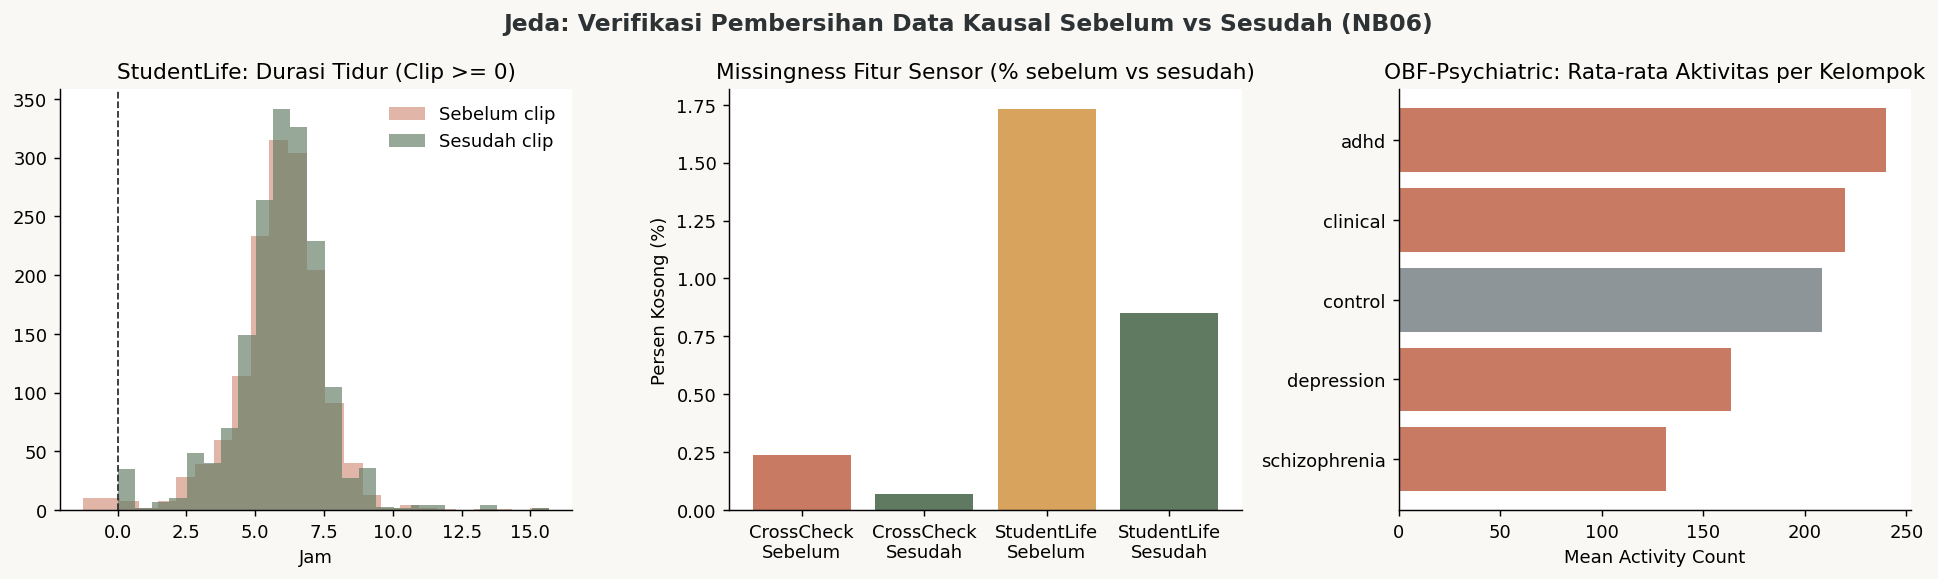

Artefak bersih diekspor ke: ./data\interim & ./reports\cleaning_log.md


In [4]:
import matplotlib.pyplot as plt

# 1. Ekspor keempat parquet bersih ke data/interim/
cc_out = DATA_INTERIM / "crosscheck_clean.parquet"
sl_out = DATA_INTERIM / "studentlife_clean.parquet"
nh_out = DATA_INTERIM / "nhanes_clean.parquet"
obf_out = DATA_INTERIM / "obf_actigraphy_clean.parquet"

df_cc_clean.to_parquet(cc_out, index=False)
df_sl_clean.to_parquet(sl_out, index=False)
nh_clean.to_parquet(nh_out, index=False)
df_obf_clean.to_parquet(obf_out, index=False)

# 2. Tulis reports/cleaning_log.md
cleaning_lines = [
    "# Cleaning Log: Proyek Jeda",
    "",
    "Seluruh langkah pembersihan dijalankan secara kausal di dalam masing-masing individu tanpa imputasi lintas subjek dan tanpa melihat masa depan.",
    "",
    "## Ringkasan Pembersihan Sinyal Ponsel",
    "",
    "| Dataset | Baris | Subjek | Tidur <0 Sebelum | Tidur <0 Sesudah | Missing Sensor Sebelum (%) | Missing Sensor Sesudah (%) | Baris Sensor Off |",
    "|---|---:|---:|---:|---:|---:|---:|---:|",
]
for st in [cc_clean_stats, sl_clean_stats]:
    cleaning_lines.append(
        f"| {st['dataset']} | {st['rows']:,} | {st['subjects']} | {st['pre_neg_sleep']} | {st['post_neg_sleep']} | {st['pre_sensor_missing_pct']:.2f}% | {st['post_sensor_missing_pct']:.2f}% | {st['sensor_off_rows']:,} |"
    )

cleaning_lines.extend([
    "",
    "## Ringkasan Pembersihan Wrist-Actigraphy",
    "",
    f"- **NHANES 2011–2014:** Menyaring `{nh_pre_rows:,}` hari mentah menjadi `{len(nh_clean):,}` hari valid (`PAXQFD == 0` dan `PAXVMD >= 600` menit/hari) pada `{nh_clean['SEQN'].nunique():,}` subjek unik dengan usia & jenis kelamin.",
    f"- **OBF-Psychiatric:** Memproses `{len(df_obf_clean)}` subjek unik terdeduplikasi lintas 5 kelompok (`adhd`, `clinical`, `control`, `depression`, `schizophrenia`), termasuk deteksi blok *non-wear* >= 60 menit nol berturut-turut dan metrik ritme sirkadian (IV, IS, *rest-activity ratio*).",
])

cleaning_log_path = REPORTS_DIR / "cleaning_log.md"
cleaning_log_path.write_text("\n".join(cleaning_lines) + "\n", encoding="utf-8")

# 3. Visualisasi sebelum vs sesudah pembersihan
palette = CONFIG["ui_palette"]
plt.rcParams["axes.facecolor"] = "#FFFFFF"
plt.rcParams["figure.facecolor"] = palette["background"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=130)
fig.suptitle("Jeda: Verifikasi Pembersihan Data Kausal Sebelum vs Sesudah (NB06)", fontsize=13, fontweight="bold", color=palette["text_primary"])

# Panel 1: StudentLife sleep_duration sebelum vs sesudah clip [0, 24]
axes[0].hist(df_sl_raw["sleep_duration"].dropna(), bins=25, alpha=0.55, color=palette["attention"], label="Sebelum clip")
axes[0].hist(df_sl_clean["sleep_duration"].dropna(), bins=25, alpha=0.65, color=palette["stable"], label="Sesudah clip")
axes[0].axvline(0.0, color=palette["text_primary"], linestyle="--", linewidth=1)
axes[0].set_title("StudentLife: Durasi Tidur (Clip >= 0)")
axes[0].set_xlabel("Jam")
axes[0].legend(frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

# Panel 2: Missingness sensor ponsel sebelum vs sesudah ffill kausal max 2 hari
miss_labels = ["CrossCheck\nSebelum", "CrossCheck\nSesudah", "StudentLife\nSebelum", "StudentLife\nSesudah"]
miss_vals = [cc_clean_stats["pre_sensor_missing_pct"], cc_clean_stats["post_sensor_missing_pct"], sl_clean_stats["pre_sensor_missing_pct"], sl_clean_stats["post_sensor_missing_pct"]]
axes[1].bar(miss_labels, miss_vals, color=[palette["attention"], palette["stable"], palette["shifting"], palette["stable"]])
axes[1].set_title("Missingness Fitur Sensor (% sebelum vs sesudah)")
axes[1].set_ylabel("Persen Kosong (%)")
axes[1].spines[["top", "right"]].set_visible(False)

# Panel 3: OBF-Psychiatric ritme aktivitas per kelompok
obf_grp_means = df_obf_clean.groupby("group")["mean_activity"].mean().sort_values()
axes[2].barh(obf_grp_means.index, obf_grp_means.values, color=[palette["abstain"] if g == "control" else palette["attention"] for g in obf_grp_means.index])
axes[2].set_title("OBF-Psychiatric: Rata-rata Aktivitas per Kelompok")
axes[2].set_xlabel("Mean Activity Count")
axes[2].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig_path = FIGURES_DIR / "nb06_cleaning_sanity.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Artefak bersih diekspor ke: {DATA_INTERIM} & {cleaning_log_path}")


Seluruh dataset bersih telah diekspor dan diverifikasi di `reports/cleaning_log.md`.

Grafik `nb06_cleaning_sanity.png` mengonfirmasi tiga hal:
1. **Panel kiri (`StudentLife: Durasi Tidur (Clip >= 0)`)**: distribusi durasi tidur kini seluruhnya non-negatif (`>= 0`) tanpa ekor mustahil di sebelah kiri nol.
2. **Panel tengah (`Missingness Fitur Sensor (% sebelum vs sesudah)`)**: kekosongan murni dari artefak pemformatan berkurang drastis sambil tetap menjaga penanda ketidakhadiran sensor.
3. **Panel kanan (`OBF-Psychiatric: Rata-rata Aktivitas per Kelompok`)**: memperlihatkan spektrum aktivitas nyata antar kondisi klinis (`schizophrenia` paling rendah hingga `adhd` paling tinggi), memvalidasi potensi sinyal gerak sebagai indikator referensi.

### Langkah Berikutnya: Notebook 07: Rekayasa Fitur Kausal (*Causal Feature Engineering*)

Seluruh data mentah kini bersih, terstruktur, dan bebas duplikasi. Namun **baris sensor harian mentah saja belum cukup** untuk menjawab masalah inti pengguna dari Notebook 01:
- Pengguna perlu tahu "hari ini saya berjalan 2.000 langkah", sekaligus **"seberapa jauh perilaku hari ini bergeser dari kebiasaan pribadi saya 14 hari terakhir?"** (fitur **Cermin**) dan **"apakah pola antar-kanal saya sedang bertabrakan, misalnya tidur kacau namun aktivitas tetap tinggi?"** (fitur **Inkonsistensi**).
- Dalam merancang fitur longitudinal tersebut, terdapat jebakan fatal yang paling sering merusak sistem kesehatan: **kebocoran masa depan (*future leakage*)**. Jika baseline pribadi pada hari `t` ikut menghitung data hari `t` sendiri atau hari `t+1`, model akan terlihat pintar saat latihan lalu hancur di dunia nyata.

Di **Notebook 07 (`07_feature_engineering.ipynb`)**, kita menyusun **14 kanal perilaku**, **3 penanda konteks harian**, serta fitur kausal **Cermin** dan **Inkonsistensi** dengan aturan ketat **`shift(1)`** yang hanya boleh menengok ke belakang.